# 04 — Compare the PPO agent with simple benchmarks

This notebook compares each seed of the active PPO experiment with two simple benchmarks over the same development-validation period.

The two benchmarks are an equal-weight portfolio of the nine sector ETFs and buy-and-hold SPY.

The PPO checkpoint was selected using development validation, so these results are for model development rather than final performance claims. The final two-year holdout remains untouched.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from experiment_config import EXPERIMENT_CONFIG

## Load the validation results and market returns

In [2]:
DATA_CONFIG = EXPERIMENT_CONFIG["data"]
ENVIRONMENT_CONFIG = EXPERIMENT_CONFIG["environment"]
ACTIVE_EXPERIMENT = EXPERIMENT_CONFIG["experiment_name"]

TRADING_DAYS_PER_YEAR = 252
REBALANCE_INTERVAL_DAYS = ENVIRONMENT_CONFIG["decision_frequency_days"]
TRANSACTION_COST_RATE = ENVIRONMENT_CONFIG["transaction_cost_rate"]
TRADABLE_SYMBOLS = DATA_CONFIG["tradable_symbols"]

ACTIVE_RESULTS_PATHS = {
    seed: (
        Path("../models") / ACTIVE_EXPERIMENT
        / f"seed_{seed}" / "validation_results.csv"
    )
    for seed in EXPERIMENT_CONFIG["training"]["seeds"]
}
FEATURE_PATH = Path(DATA_CONFIG["feature_path"])

In [3]:
active_results_by_seed = {
    seed: (
        pd.read_csv(path, parse_dates=["date"])
        .set_index("date")
        .sort_index()
    )
    for seed, path in ACTIVE_RESULTS_PATHS.items()
}
market_returns = pd.read_csv(
    FEATURE_PATH,
    usecols=["date", "symbol", "tradable", "return_1d"],
    parse_dates=["date"],
)

validation_dates = next(iter(active_results_by_seed.values())).index
validation_rows = market_returns.loc[
    market_returns["date"].isin(validation_dates)
]
sector_returns = (
    validation_rows.loc[validation_rows["tradable"]]
    .pivot(index="date", columns="symbol", values="return_1d")
    .reindex(index=validation_dates, columns=TRADABLE_SYMBOLS)
)
spy_returns = (
    validation_rows.loc[validation_rows["symbol"] == "SPY"]
    .set_index("date")["return_1d"]
    .reindex(validation_dates)
)

print(
    f"Comparison period: {validation_dates.min().date()} through "
    f"{validation_dates.max().date()} ({len(validation_dates)} days)"
)

Comparison period: 2019-08-27 through 2024-09-30 (1282 days)


## Construct the benchmarks

The equal-weight portfolio uses the active experiment's decision frequency and transaction-cost rate. Between rebalances, its weights drift with sector returns. SPY is treated as buy-and-hold with no ongoing trading cost.

In [4]:
def drift_weights(weights, asset_returns):
    """Update portfolio weights after one day of asset returns."""
    portfolio_return = weights @ asset_returns
    return weights * (1 + asset_returns) / (1 + portfolio_return)


def run_equal_weight_benchmark(returns):
    """Run a periodically rebalanced equal-weight sector portfolio."""
    equal_weights = np.full(returns.shape[1], 1 / returns.shape[1])
    weights = equal_weights.copy()
    records = []

    for position, (date, daily_returns) in enumerate(returns.iterrows()):
        rebalance = position > 0 and position % REBALANCE_INTERVAL_DAYS == 0
        turnover = (
            np.abs(equal_weights - weights).sum() if rebalance else 0.0
        )
        if rebalance:
            weights = equal_weights.copy()

        asset_returns = daily_returns.to_numpy()
        gross_return = float(weights @ asset_returns)
        transaction_cost = TRANSACTION_COST_RATE * turnover

        records.append(
            {
                "date": date,
                "gross_return": gross_return,
                "net_return": gross_return - transaction_cost,
                "turnover": turnover,
                "transaction_cost": transaction_cost,
                "short_borrow_cost": 0.0,
                "gross_exposure": 1.0,
                "short_exposure": 0.0,
            }
        )
        weights = drift_weights(weights, asset_returns)

    return pd.DataFrame(records).set_index("date")


def run_spy_benchmark(returns):
    """Represent buy-and-hold SPY over the comparison period."""
    return pd.DataFrame(
        {
            "gross_return": returns,
            "net_return": returns,
            "turnover": 0.0,
            "transaction_cost": 0.0,
            "short_borrow_cost": 0.0,
            "gross_exposure": 1.0,
            "short_exposure": 0.0,
        },
        index=returns.index,
    )

In [5]:
equal_weight_results = run_equal_weight_benchmark(sector_returns)
spy_results = run_spy_benchmark(spy_returns)

strategy_results = {
    **{
        f"PPO: {ACTIVE_EXPERIMENT}, seed {seed}": results
        for seed, results in active_results_by_seed.items()
    },
    "Equal-weight sectors": equal_weight_results,
    "SPY buy-and-hold": spy_results,
}

## Compare validation performance

In [6]:
def calculate_metrics(results):
    """Calculate performance and implementation metrics."""
    returns = results["net_return"]
    cumulative_return = (1 + returns).prod() - 1
    annualized_return = (
        (1 + cumulative_return)
        ** (TRADING_DAYS_PER_YEAR / len(returns))
        - 1
    )
    annualized_volatility = returns.std() * np.sqrt(TRADING_DAYS_PER_YEAR)
    wealth = (1 + returns).cumprod()
    drawdown = wealth / wealth.cummax() - 1
    return pd.Series(
        {
            "cumulative return": cumulative_return,
            "annualized return": annualized_return,
            "annualized volatility": annualized_volatility,
            "Sharpe ratio": (
                returns.mean() / returns.std()
                * np.sqrt(TRADING_DAYS_PER_YEAR)
            ),
            "maximum drawdown": drawdown.min(),
            "annualized turnover": (
                results["turnover"].mean() * TRADING_DAYS_PER_YEAR
            ),
            "average gross exposure": results["gross_exposure"].mean(),
            "average short exposure": results["short_exposure"].mean(),
            "annualized implementation cost": (
                (
                    results["transaction_cost"]
                    + results["short_borrow_cost"]
                ).mean()
                * TRADING_DAYS_PER_YEAR
            ),
        }
    )


comparison_table = pd.DataFrame(
    {
        strategy: calculate_metrics(results)
        for strategy, results in strategy_results.items()
    }
).T
display(comparison_table.style.format("{:.3f}"))

,cumulative return,annualized return,annualized volatility,Sharpe ratio,maximum drawdown,annualized turnover,average gross exposure,average short exposure,annualized implementation cost
"PPO: long_short_scaled, seed 42",1.747,0.220,0.244,0.936,-0.347,16.687,1.584,0.292,0.011
Equal-weight sectors,1.029,0.149,0.204,0.785,-0.369,0.720,1.000,0.000,0.000
SPY buy-and-hold,1.162,0.164,0.207,0.835,-0.337,0.000,1.000,0.000,0.000


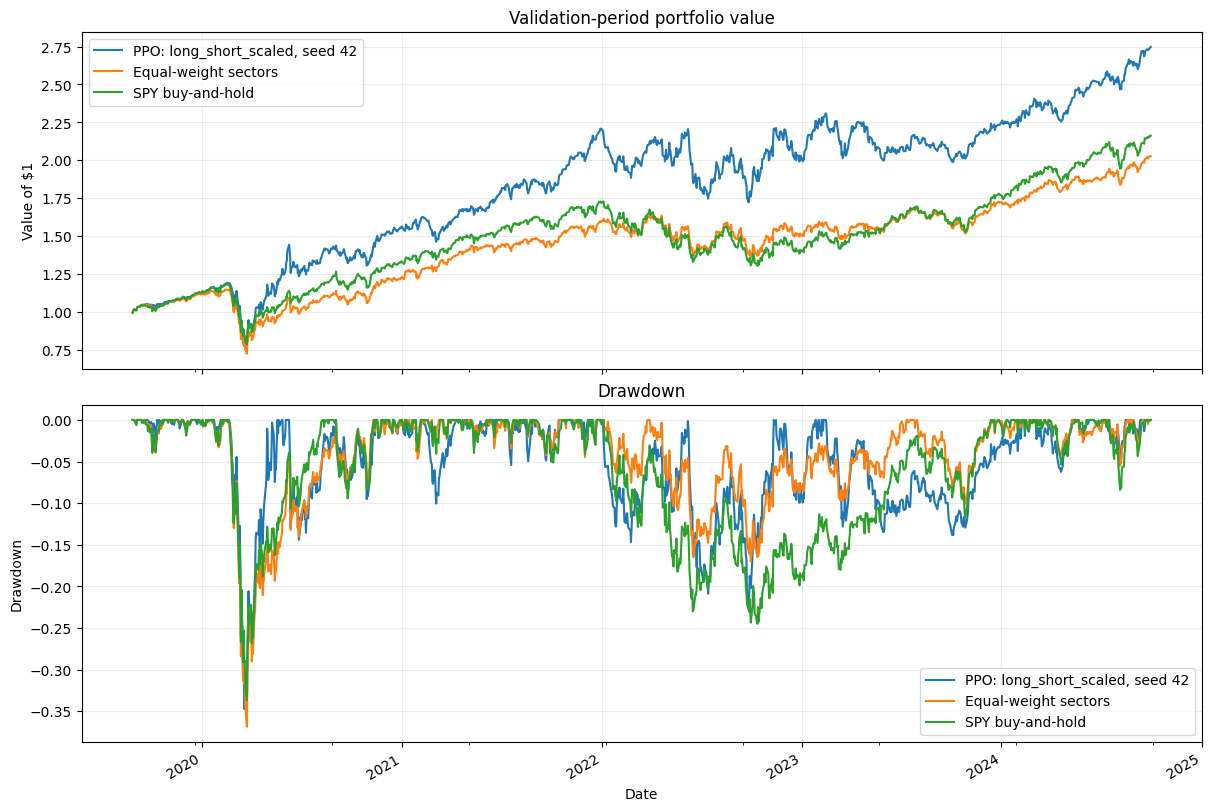

In [7]:
wealth = pd.DataFrame(
    {
        strategy: (1 + results["net_return"]).cumprod()
        for strategy, results in strategy_results.items()
    }
)
drawdowns = wealth / wealth.cummax() - 1

figure, axes = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True, constrained_layout=True
)
wealth.plot(ax=axes[0])
axes[0].set_title("Validation-period portfolio value")
axes[0].set_ylabel("Value of $1")

drawdowns.plot(ax=axes[1])
axes[1].set_title("Drawdown")
axes[1].set_ylabel("Drawdown")
axes[1].set_xlabel("Date")

for axis in axes:
    axis.grid(alpha=0.25)

plt.show()

## PPO portfolio weights by seed

The chart shows each seed's executed portfolio weights. The agent remains 100% net invested, and its gross-exposure limit is recorded in the experiment configuration.

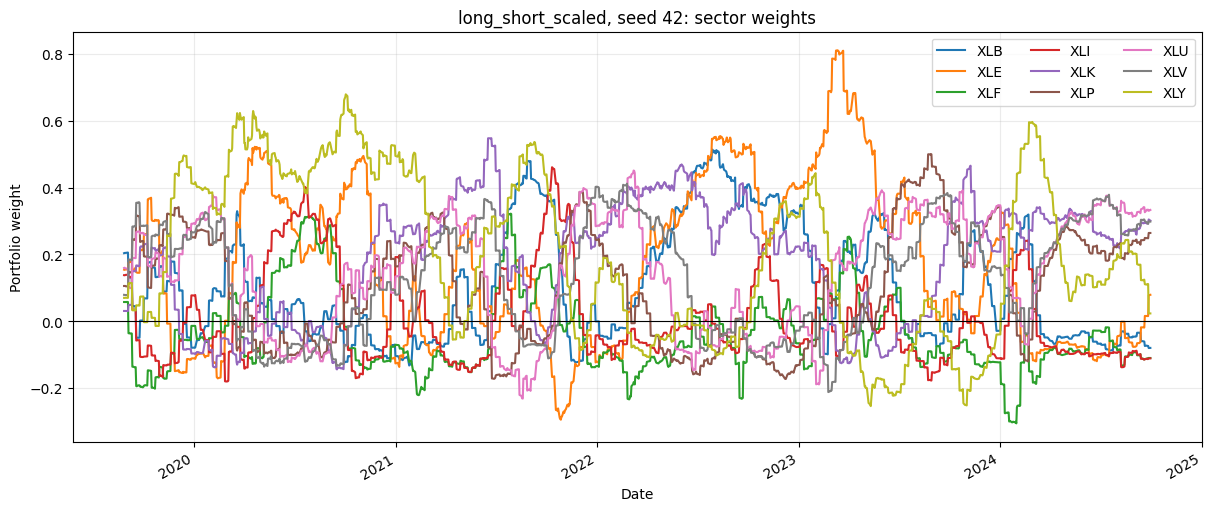

In [8]:
weight_columns = [f"weight_{symbol}" for symbol in TRADABLE_SYMBOLS]

for seed, active_results in active_results_by_seed.items():
    figure, axis = plt.subplots(figsize=(12, 5), constrained_layout=True)
    active_results[weight_columns].rename(
        columns={f"weight_{symbol}": symbol for symbol in TRADABLE_SYMBOLS}
    ).plot(ax=axis)
    axis.axhline(0, color="black", linewidth=0.8)
    axis.set_title(f"{ACTIVE_EXPERIMENT}, seed {seed}: sector weights")
    axis.set_ylabel("Portfolio weight")
    axis.set_xlabel("Date")
    axis.legend(ncol=3)
    axis.grid(alpha=0.25)
    plt.show()


## Calendar-year returns

In [9]:
calendar_year_returns = (
    pd.concat(
        {
            strategy: results["net_return"]
            for strategy, results in strategy_results.items()
        },
        axis=1,
    )
    .groupby(lambda date: date.year)
    .apply(lambda returns: (1 + returns).prod() - 1)
)
calendar_year_returns.index.name = "year"
display(calendar_year_returns.style.format("{:.1%}"))

,"PPO: long_short_scaled, seed 42",Equal-weight sectors,SPY buy-and-hold
year,,,
2019,12.4%,11.9%,12.8%
2020,39.2%,10.1%,18.3%
2021,41.1%,29.7%,28.7%
2022,-8.0%,-5.3%,-18.2%
2023,10.0%,13.9%,26.2%
2024,23.0%,17.9%,21.9%


## Save the comparison

In [10]:
RESULTS_DIRECTORY = Path("../results")
RESULTS_DIRECTORY.mkdir(parents=True, exist_ok=True)

daily_comparison = pd.concat(
    strategy_results, names=["strategy", "date"]
).reset_index()
daily_comparison.to_csv(
    RESULTS_DIRECTORY / "daily_validation_strategy_comparison.csv",
    index=False,
)
comparison_table.to_csv(
    RESULTS_DIRECTORY / "daily_validation_strategy_metrics.csv",
    index_label="strategy",
)